# Amplitude Amplification — Reflection Operators `R_good` and `R_A` (Qiskit)

**Chapter / concept:** Amplitude Amplification, general reflection-operator formalism
`Q = R_A · R_good` (this generalizes the earlier Grover-diffusion chapter, which used
the special case `A = H^⊗n`).

**Circuit:** 2-qubit amplitude amplification with a **general, non-uniform** state
preparation operator `A = RY(theta0) (x) RY(theta1)` (not a Hadamard!), a target/oracle
reflection `R_good` that marks `|11>`, and the reflection-about-the-initial-state
`R_A = A (2|00><00| - I) A^dagger`. One full amplification iteration `Q = R_A . R_good`
is applied on top of `A|00>`.

## SETUP (identical in the matched CUDA-Q notebook)
- **N_QUBITS** = 2
- **THETA0** = pi/3, **THETA1** = pi/4  (RY rotation angles defining `A`)
- **Gate sequence:**
  1. **State prep A:** `RY(THETA0, q0)`, `RY(THETA1, q1)` — prepares `A|00>`, a
     *non-uniform* superposition (unlike the earlier chapter's `H⊗H`)
  2. **Oracle reflection R_good:** `CZ(q0,q1)` — for a single marked basis state
     `|11>`, `CZ == I - 2|11><11|` exactly, so this already IS the reflection operator,
     no extra construction needed
  3. **Reflection R_A = A (2|00><00| - I) A^dagger**, built as its own 3-part circuit:
     - `A^dagger`: `RY(-THETA0, q0)`, `RY(-THETA1, q1)`
     - reflect about `|00>`: `X(q0)`, `X(q1)`, `CZ(q0,q1)`, `X(q0)`, `X(q1)`
     - `A`: `RY(THETA0, q0)`, `RY(THETA1, q1)`
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook).
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}`, ascending binary order.

## Theory recap
Let `a = |<11|A|00>|^2` be the initial success probability and `theta = arcsin(sqrt(a))`.
The general amplitude-amplification theorem states that for ANY state-preparation
operator `A` (not just Hadamard), applying `Q = R_A . R_good` keeps the state inside
the 2-D real subspace spanned by the "good" and "bad" components, rotating it by angle
`2*theta` per iteration, so that after `k` iterations:

`P(good) = sin((2k+1) * theta)^2`

With `THETA0 = pi/3`, `THETA1 = pi/4`: `a = sin(THETA0/2)^2 * sin(THETA1/2)^2 ≈ 0.036612`,
`theta ≈ 0.192529 rad ≈ 11.031 deg`, so after **k=1** iteration:

`P(|11>) = sin(3*theta)^2 ≈ 0.298120`

**Reflection-operator sanity checks (both notebooks assert these before trusting results):**
`R_good^2 = I`, `R_A^2 = I` (both are involutions), and both are Hermitian — the
defining properties of a reflection operator. Note: the circuit `X^2 CZ X^2` that
implements "reflect about `|00>`" carries an overall global phase of -1 relative to the
textbook matrix `2|00><00| - I` (same well-known artifact as the H-X-CZ-X-H diffuser in
the earlier chapter) — this does not change `R_A^2 = I` and does not affect any
measured probability, which is confirmed numerically below.

**Run all cells top to bottom.**


In [5]:
# Install (uncomment if running in a fresh environment)
# pip install -q qiskit qiskit-aer pylatexenc


In [4]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [6]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

N_QUBITS = 2
SHOTS = 10000
SEED = 42
THETA0 = np.pi / 3
THETA1 = np.pi / 4
TOPIC_SLUG = "aa_reflection_operators"

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"THETA0   = {THETA0} rad ({np.degrees(THETA0):.4f} deg)")
print(f"THETA1   = {THETA1} rad ({np.degrees(THETA1):.4f} deg)")


N_QUBITS = 2
SHOTS    = 10000
SEED     = 42
THETA0   = 1.0471975511965976 rad (60.0000 deg)
THETA1   = 0.7853981633974483 rad (45.0000 deg)


In [7]:
# Build the circuit gate-by-gate: state prep A, then one AA iteration Q = R_A . R_good.
# Qiskit convention: qubit 0 is the rightmost bit -> matches our contract, no changes needed.

qc = QuantumCircuit(N_QUBITS, name="AA_1_iteration_general_A")

# --- State preparation A = RY(THETA0) (x) RY(THETA1): a NON-uniform initial state ---
qc.ry(THETA0, 0)   # qubit 0 -> cos(THETA0/2)|0> + sin(THETA0/2)|1>
qc.ry(THETA1, 1)   # qubit 1 -> cos(THETA1/2)|0> + sin(THETA1/2)|1>
qc.barrier(label="A")

# --- Oracle / target reflection R_good: marks |11> ---
qc.cz(0, 1)   # CZ == I - 2|11><11| exactly (a genuine reflection about the "good" state)
qc.barrier(label="R_good")

# --- Reflection about the initial state: R_A = A (2|00><00| - I) A^dagger ---
qc.ry(-THETA0, 0)   # A^dagger part 1
qc.ry(-THETA1, 1)   # A^dagger part 2
qc.x(0); qc.x(1)     # map |00> -> |11>
qc.cz(0, 1)           # phase-flip |11> (== phase flip of |00> pre-X)
qc.x(0); qc.x(1)     # undo the X layer
qc.ry(THETA0, 0)    # A part 1
qc.ry(THETA1, 1)    # A part 2
qc.barrier(label="R_A")

print(qc)


     ┌─────────┐ A     R_good ┌──────────┐┌───┐   ┌───┐┌─────────┐ R_A 
q_0: ┤ Ry(π/3) ├─░──■────░────┤ Ry(-π/3) ├┤ X ├─■─┤ X ├┤ Ry(π/3) ├──░──
     ├─────────┤ ░  │    ░    ├──────────┤├───┤ │ ├───┤├─────────┤  ░  
q_1: ┤ Ry(π/4) ├─░──■────░────┤ Ry(-π/4) ├┤ X ├─■─┤ X ├┤ Ry(π/4) ├──░──
     └─────────┘ ░       ░    └──────────┘└───┘   └───┘└─────────┘  ░  


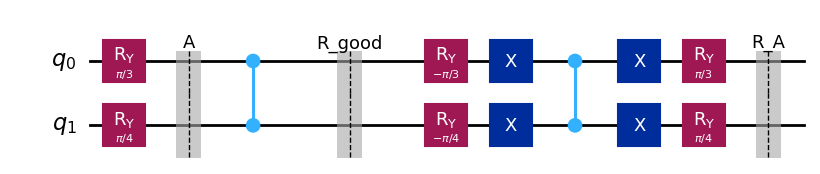

In [8]:
# Draw the circuit with matplotlib and save it.
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", bbox_inches="tight", dpi=150)
fig


In [9]:
!pip install -q qiskit qiskit-aer cudaq matplotlib pylatexenc

In [10]:
import qiskit
import qiskit_aer

print("Qiskit version:", qiskit.__version__)
print("Qiskit Aer loaded successfully!")

Qiskit version: 2.5.1
Qiskit Aer loaded successfully!


In [11]:
import cudaq

print("CUDA-Q loaded successfully!")

CUDA-Q loaded successfully!


In [12]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

import cudaq

print("Everything is ready!")

Everything is ready!


In [13]:
%pip install qiskit qiskit-aer

In [14]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

# Explicit matrix representation of R_good AND R_A separately (this chapter's focus),
# built two independent ways and cross-checked, plus reflection-property assertions.
np.set_printoptions(precision=4, suppress=True)

# --- (a) Hand-built from individual gate matrices (NumPy) ---
def RY(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]])

X1 = np.array([[0, 1], [1, 0]])

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

# Fix: Reverse the order of RY matrices to match Qiskit's tensor product convention
# Qiskit applies RY(THETA0) to qubit 0 and RY(THETA1) to qubit 1.
# In a 2-qubit system, this implies a tensor product of RY(THETA1) \otimes RY(THETA0).
A_hand = kron_all([RY(THETA1), RY(THETA0)]) # Changed from [RY(THETA0), RY(THETA1)]
A_dag_hand = A_hand.conj().T
Xn = kron_all([X1, X1])
CZ = np.eye(4)
CZ[3, 3] = -1   # flips |11> (index 3 in ascending-binary basis)

R_good_hand = CZ.copy()
R_A_hand = A_hand @ (Xn @ CZ @ Xn) @ A_dag_hand
Q_hand = R_A_hand @ R_good_hand

print("A (hand-built):\n", A_hand)
print("\nR_good (hand-built):\n", R_good_hand)
print("\nR_A (hand-built):\n", R_A_hand)
print("\nQ = R_A . R_good (hand-built):\n", Q_hand)

# --- (b) Extracted directly from Qiskit circuits via Operator() ---
A_qc = QuantumCircuit(N_QUBITS)
A_qc.ry(THETA0, 0); A_qc.ry(THETA1, 1)
A_qiskit = Operator(A_qc).data

R_good_qc = QuantumCircuit(N_QUBITS)
R_good_qc.cz(0, 1)
R_good_qiskit = Operator(R_good_qc).data

R_A_qc = QuantumCircuit(N_QUBITS)
R_A_qc.ry(-THETA0, 0); R_A_qc.ry(-THETA1, 1)
R_A_qc.x(0); R_A_qc.x(1)
R_A_qc.cz(0, 1)
R_A_qc.x(0); R_A_qc.x(1)
R_A_qc.ry(THETA0, 0); R_A_qc.ry(THETA1, 1)
R_A_qiskit = Operator(R_A_qc).data

Q_qiskit = R_A_qiskit @ R_good_qiskit

print("\nA matches (hand vs Qiskit Operator):", np.allclose(A_hand, A_qiskit))
print("R_good matches (hand vs Qiskit Operator):", np.allclose(R_good_hand, R_good_qiskit))
print("R_A matches (hand vs Qiskit Operator):", np.allclose(R_A_hand, R_A_qiskit))
print("Q matches (hand vs Qiskit Operator):", np.allclose(Q_hand, Q_qiskit))

assert np.allclose(A_hand, A_qiskit)
assert np.allclose(R_good_hand, R_good_qiskit)
assert np.allclose(R_A_hand, R_A_qiskit)
assert np.allclose(Q_hand, Q_qiskit)

# --- Reflection-operator property checks (defining properties of R_good, R_A) ---
print("\nR_good^2 == I:", np.allclose(R_good_qiskit @ R_good_qiskit, np.eye(4)))
print("R_good is Hermitian:", np.allclose(R_good_qiskit, R_good_qiskit.conj().T))
print("R_A^2 == I:", np.allclose(R_A_qiskit @ R_A_qiskit, np.eye(4)))
print("R_A is Hermitian:", np.allclose(R_A_qiskit, R_A_qiskit.conj().T))


assert np.allclose(R_good_qiskit @ R_good_qiskit, np.eye(4))
assert np.allclose(R_good_qiskit, R_good_qiskit.conj().T)
assert np.allclose(R_A_qiskit @ R_A_qiskit, np.eye(4))
assert np.allclose(R_A_qiskit, R_A_qiskit.conj().T)

A (hand-built):
 [[ 0.8001 -0.4619 -0.3314  0.1913]
 [ 0.4619  0.8001 -0.1913 -0.3314]
 [ 0.3314 -0.1913  0.8001 -0.4619]
 [ 0.1913  0.3314  0.4619  0.8001]]

R_good (hand-built):
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]

R_A (hand-built):
 [[-0.2803 -0.7392 -0.5303 -0.3062]
 [-0.7392  0.5732 -0.3062 -0.1768]
 [-0.5303 -0.3062  0.7803 -0.1268]
 [-0.3062 -0.1768 -0.1268  0.9268]]

Q = R_A . R_good (hand-built):
 [[-0.2803 -0.7392 -0.5303  0.3062]
 [-0.7392  0.5732 -0.3062  0.1768]
 [-0.5303 -0.3062  0.7803  0.1268]
 [-0.3062 -0.1768 -0.1268 -0.9268]]

A matches (hand vs Qiskit Operator): True
R_good matches (hand vs Qiskit Operator): True
R_A matches (hand vs Qiskit Operator): True
Q matches (hand vs Qiskit Operator): True

R_good^2 == I: True
R_good is Hermitian: True
R_A^2 == I: True
R_A is Hermitian: True


In [15]:
# Exact statevector, with global-phase normalization applied.

def normalize_global_phase(vec):
    vec = np.asarray(vec, dtype=complex)
    idx = np.argmax(np.abs(vec) > 1e-9)
    phase = np.angle(vec[idx])
    return vec * np.exp(-1j * phase)

sv_circuit = qc.copy()
sv = Statevector.from_instruction(sv_circuit).data

# Qiskit already indexes amplitudes with qubit 0 as the rightmost bit -> no reversal needed.
sv_normalized = normalize_global_phase(sv)

probs_qiskit_sv = {format(i, f"0{N_QUBITS}b"): float(abs(sv_normalized[i]) ** 2)
                    for i in range(2 ** N_QUBITS)}
probs_qiskit_sv = dict(sorted(probs_qiskit_sv.items()))

print("Statevector (phase-normalized):", sv_normalized)
print("\nProbability dictionary (statevector):")
for k, v in probs_qiskit_sv.items():
    print(f"  |{k}> : {v:.6f}")

a = np.sin(THETA0 / 2) ** 2 * np.sin(THETA1 / 2) ** 2
theta = np.arcsin(np.sqrt(a))
expected_p11 = np.sin(3 * theta) ** 2
print(f"\nHand-derived a = {a:.6f}, theta = {theta:.6f} rad")
print(f"Hand-derived theoretical P(|11>) after 1 iteration = sin(3*theta)^2 = {expected_p11:.6f}")
print(f"Statevector P(|11>) = {probs_qiskit_sv['11']:.6f}")
assert abs(probs_qiskit_sv['11'] - expected_p11) < 1e-6


Statevector (phase-normalized): [0.6829+0.j 0.3943+0.j 0.2829+0.j 0.546 +0.j]

Probability dictionary (statevector):
  |00> : 0.466394
  |01> : 0.155465
  |10> : 0.080021
  |11> : 0.298120

Hand-derived a = 0.036612, theta = 0.192529 rad
Hand-derived theoretical P(|11>) after 1 iteration = sin(3*theta)^2 = 0.298120
Statevector P(|11>) = 0.298120


### Ordering-fix note (Qiskit)

**No bitstring reversal was applied.** Qiskit's `Statevector` and `AerSimulator`
counts both natively index qubit 0 as the least-significant (rightmost) bit, matching
the QUBIT ORDERING CONTRACT above. This notebook's dictionaries can be compared
directly to the phase-normalized, bit-order-corrected CUDA-Q results.


In [16]:
# Measurement: add measurements, run with the shared SEED/SHOTS, get counts -> probabilities.
meas_qc = qc.copy()
meas_qc.measure_all()

sim = AerSimulator(seed_simulator=SEED)
compiled = transpile(meas_qc, sim)
job = sim.run(compiled, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

# Qiskit's measure_all() counts keys already use qubit 0 = rightmost bit -> no reversal needed.
probs_qiskit_counts = {k: v / SHOTS for k, v in counts.items()}
for k in [format(i, f"0{N_QUBITS}b") for i in range(2 ** N_QUBITS)]:
    probs_qiskit_counts.setdefault(k, 0.0)
probs_qiskit_counts = dict(sorted(probs_qiskit_counts.items()))

print("Raw counts:", counts)
print("\nProbabilities from sampling:")
for k, v in probs_qiskit_counts.items():
    print(f"  |{k}> : {v:.4f}")


Raw counts: {'11': 3000, '10': 830, '00': 4590, '01': 1580}

Probabilities from sampling:
  |00> : 0.4590
  |01> : 0.1580
  |10> : 0.0830
  |11> : 0.3000


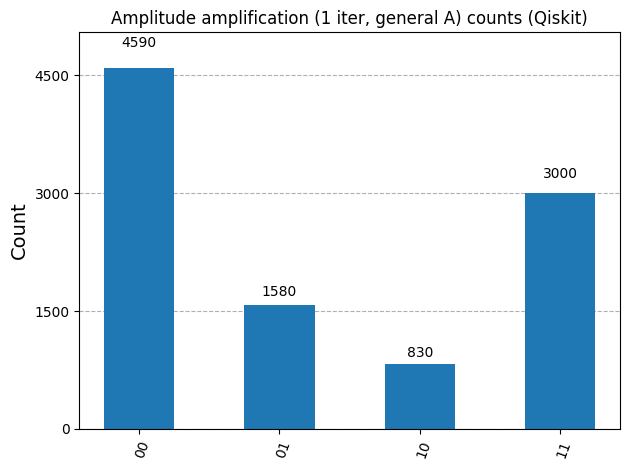

In [17]:
# Histogram (matplotlib), saved to file.
fig2 = plot_histogram(counts, title="Amplitude amplification (1 iter, general A) counts (Qiskit)")
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", bbox_inches="tight", dpi=150)
fig2


In [18]:
# Resource counts.
depth = qc.depth()
gate_counts = qc.count_ops()
print(f"Circuit depth (before transpile): {depth}")
print(f"Gate counts: {dict(gate_counts)}")

depth_transpiled = compiled.depth()
gate_counts_transpiled = compiled.count_ops()
print(f"\nTranspiled circuit depth (as actually run on AerSimulator): {depth_transpiled}")
print(f"Transpiled gate counts: {dict(gate_counts_transpiled)}")


Circuit depth (before transpile): 7
Gate counts: {'ry': 6, 'x': 4, 'barrier': 3, 'cz': 2}

Transpiled circuit depth (as actually run on AerSimulator): 6
Transpiled gate counts: {'barrier': 4, 'u3': 4, 'ry': 2, 'measure': 2, 'cz': 1, 'cp': 1}


In [19]:
# Convention-notes (plain text restatement).
print("Ordering fix applied: NONE. Qiskit already uses qubit 0 = rightmost bit,")
print("matching the QUBIT ORDERING CONTRACT, so no reversal was needed anywhere.")
print()
print("Phase convention applied: multiplied the full statevector by exp(-1j*phase),")
print("where phase = angle of the first amplitude (ascending bitstring order) with")
print("abs(amplitude) > 1e-9, so that amplitude becomes real and positive.")
print()
print("Reflection operators: R_good = CZ = I - 2|11><11| exactly (single marked state).")
print("R_A = A (2|00><00|-I) A^dagger, built as A^dagger -> reflect-about-|00> -> A.")
print("Both were verified to satisfy R^2=I and R=R^dagger (true reflections) above.")


Ordering fix applied: NONE. Qiskit already uses qubit 0 = rightmost bit,
matching the QUBIT ORDERING CONTRACT, so no reversal was needed anywhere.

Phase convention applied: multiplied the full statevector by exp(-1j*phase),
where phase = angle of the first amplitude (ascending bitstring order) with
abs(amplitude) > 1e-9, so that amplitude becomes real and positive.

Reflection operators: R_good = CZ = I - 2|11><11| exactly (single marked state).
R_A = A (2|00><00|-I) A^dagger, built as A^dagger -> reflect-about-|00> -> A.
Both were verified to satisfy R^2=I and R=R^dagger (true reflections) above.


In [20]:
# Final result dictionary.
QISKIT_RESULT = probs_qiskit_counts
print("QISKIT_RESULT =", QISKIT_RESULT)


QISKIT_RESULT = {'00': 0.459, '01': 0.158, '10': 0.083, '11': 0.3}


In [21]:
# --- Diff-check block (uncomment and run after producing CUDAQ_RESULT in the matched notebook) ---
#
# Hand-computed expected result (theory, exact statevector probabilities):
#   a = sin(THETA0/2)^2 * sin(THETA1/2)^2 = 0.036612
#   theta = arcsin(sqrt(a)) = 0.192529 rad (11.031 deg)
#   P(|11>) after 1 AA iteration = sin(3*theta)^2 = 0.298120
#   Full exact statevector-probability dict (from independent NumPy simulation):
#
# EXPECTED_RESULT = {"00": 0.466394, "01": 0.080021, "10": 0.155465, "11": 0.298120}
#
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT) | set(EXPECTED_RESULT)
# max_delta_qiskit_vs_expected = max(abs(QISKIT_RESULT.get(k, 0.0) - EXPECTED_RESULT.get(k, 0.0)) for k in all_keys)
# max_delta_qiskit_vs_cudaq    = max(abs(QISKIT_RESULT.get(k, 0.0) - CUDAQ_RESULT.get(k, 0.0)) for k in all_keys)
#
# print("Max |QISKIT_RESULT - EXPECTED_RESULT| =", max_delta_qiskit_vs_expected)
# print("Max |QISKIT_RESULT - CUDAQ_RESULT|    =", max_delta_qiskit_vs_cudaq)
#
# assert max_delta_qiskit_vs_expected < 1e-2   # sampling noise at 10000 shots
# assert max_delta_qiskit_vs_cudaq < 1e-2
# print("PASS: results agree within tolerance.")
